<font color=skyblue> **Sampling from a density function**</font>
 
 目標： 從一個已知的密度函數 $f(x)$ 抽樣。
 

<font color=yellowgreen> **方法一：反函數法 (Inverse Transform Method)**</font>
 
 Step 1. 計算累積分佈函數 (CDF)：
    $$
    F(x) = \int_{-\infty}^{x} f(t) dt
    $$
 Step 2. 計算反函數：
    $$
    F^{-1}(u), \quad u \sim U(0,1)
    $$
 Step 3. 抽樣：

   - 從均勻分佈 $U(0,1)$ 抽取樣本 $u$。
   - 計算 $x = F^{-1}(u)$，即為從密度函數 $f(x)$ 抽取的樣本。

Example: 
- 若 $f(x)$ 為指數分佈，則 $F(x) = 1 - e^{-\lambda x}$，反函數為 $$F^{-1}(u) = -\frac{1}{\lambda} \ln(1-u)$$
- 若 $f(x)$ 為常態分佈，則 $F(x)$ 無閉式反函數，需使用數值方法或其他抽樣技術。

<font color=yellow> 指數分佈抽樣範例：</font>

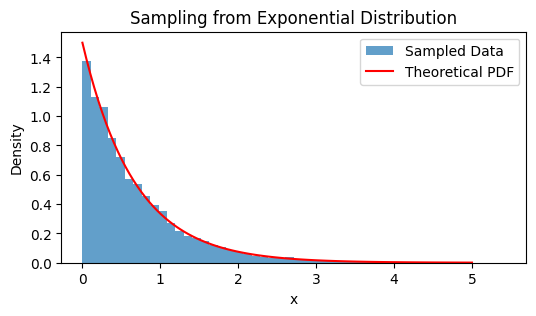

In [4]:
# use inverse function method to sample from exponential distribution
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import expon as exp

n = 10000  # number of samples
lambda_param = 1.5  # rate parameter for exponential distribution

# Generate uniform random samples
u = np.random.uniform(0, 1, n)

# Apply the inverse CDF to transform the uniform samples to exponential distribution
x = -np.log(1 - u) / lambda_param

# Plot the histogram of the sampled data
# also plot the theoretical PDF for comparison
x_values = np.linspace(0, 5, 100)
theoretical_pdf = exp.pdf(x_values, scale=1/lambda_param)
fig, ax = plt.subplots(figsize=(6, 3))
plt.hist(x, bins=50, density=True, alpha=0.7, label='Sampled Data')
plt.plot(x_values, theoretical_pdf, 'r-', label='Theoretical PDF')
plt.xlabel('x')
plt.ylabel('Density')
plt.title('Sampling from Exponential Distribution')
plt.legend()
plt.show()

<font color=yellow> 常態分布抽樣範例：</font>

use scipy.stats.norm.ppf to compute the inverse CDF (percent point function) for normal distribution.


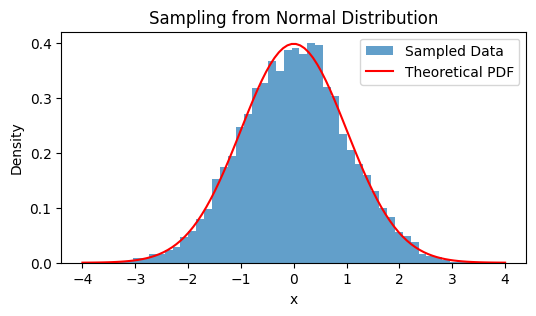

In [ ]:
# use norm.ppf to sample from normal distribution
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

n = 10000  # number of samples
mu = 0  # mean of the normal distribution
sigma = 1  # standard deviation of the normal distribution

# Generate uniform random samples
u = np.random.uniform(0, 1, n)

# Apply the inverse CDF (percent point function) to transform the uniform samples to normal distribution
x = norm.ppf(u, loc=mu, scale=sigma)

# Plot the histogram of the sampled data
# also plot the theoretical PDF for comparison
x_values = np.linspace(-4, 4, 100)
theoretical_pdf = norm.pdf(x_values, loc=mu, scale=sigma)
fig, ax = plt.subplots(figsize=(6, 3))
plt.hist(x, bins=50, density=True, alpha=0.7, label='Sampled Data')
plt.plot(x_values, theoretical_pdf, 'r-', label='Theoretical PDF')
plt.xlabel('x')
plt.ylabel('Density')
plt.title('Sampling from Normal Distribution')
plt.legend()
plt.show()


<font color=yellow> 常態分布抽樣範例：</font>

Solve the equation $F(x) = u$ numerically to find $x$ for a given $u$, i.e., use root-finding methods like Newton-Raphson or bisection method, i.e., solve $$F(x) - u = 0$$ for $x$, and 

$$F(x) = \int_{-\infty}^{x} f(t) dt$$

In [8]:

u = 0.5
# define a function g(x) = F(x) - u, where F is the CDF of the normal distribution

# def g(x):
#     return norm.cdf(x, loc=mu, scale=sigma) - u

g = lambda x: norm.cdf(x, loc=mu, scale=sigma) - u

# compute the root of g(x) using a numerical method (e.g., bisection, Newton-Raphson, etc.)
from scipy.optimize import bisect

root = bisect(g, -10, 10)
print(f"The root of g(x) is: {root}")

The root of g(x) is: 0.0


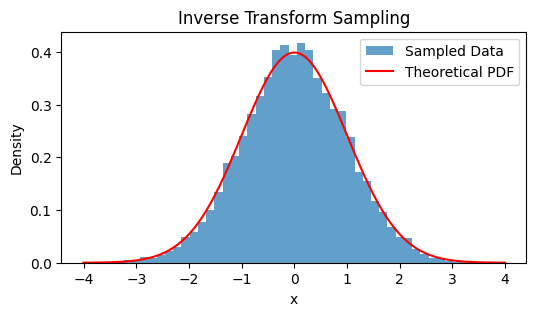

In [21]:
from scipy.optimize import brentq, newton

# generate uniform random samples
n = 10000
u = np.random.uniform(0, 1, n)

g = lambda x: norm.cdf(x, loc=mu, scale=sigma)
pdf = lambda x: norm.pdf(x, loc=mu, scale=sigma)

# compute the roots of g(x) for each u

# x = [brentq(lambda x: g(x) - u[i], -10, 10) for i in range(n)]
x = [newton(lambda x: g(x) - u[i], 0, fprime=pdf) for i in range(n)]
# def g(u, x):
#     return norm.cdf(x, loc=mu, scale=sigma) - u

# x = [bisect(lambda x: g(u[i], x), -10, 10) for i in range(n)]

# plot the histogram of the sampled data
x_values = np.linspace(-4, 4, 100)
theoretical_pdf = norm.pdf(x_values, loc=mu, scale=sigma)
fig, ax = plt.subplots(figsize=(6, 3))
plt.hist(x, bins=50, density=True, alpha=0.7, label='Sampled Data')
plt.plot(x_values, theoretical_pdf, 'r-', label='Theoretical PDF')
plt.xlabel('x')
plt.ylabel('Density')
plt.title('Inverse Transform Sampling')
plt.legend()
plt.show()


<font color=yellowgreen>方法二：Numerical CDF tabulation</font>
 
   1. 計算累積分佈函數 (CDF)：
      $$
      F(x) = \int_{-\infty}^{x} f(t) dt
      $$
   2. 將 CDF 數值化，建立一個查找表`cdf_table`。可預先儲存。
   3. 抽樣：
      - 從均勻分佈 $U(0,1)$ 抽取樣本 $u$。
      - 使用查找表找到對應的 $x$ 值，使得 $F(x) \approx u$。亦可加入插值法（linear interpolation）以提高精度。

<font color=yellowgreen> 方法三：接受-拒絕法 (Acceptance-Rejection Method)</font>
 
 1. 選擇一個簡單的提議密度函數（proposal density function） $g(x)$，使得 $f(x) \leq M g(x)$ 對所有 $x$ 成立，其中 $M$ 為常數。
 2. 抽樣：
    - 從 $g(x)$ 抽取樣本 $x^*$。
    - 從均勻分佈 $U(0,1)$ 抽取樣本 $u$。
    - 若 $u \leq \frac{f(x^*)}{M g(x^*)}$，則接受 $x^*$；否則拒絕並重複抽樣。

<font color=yellow> 常態分佈抽樣範例：</font>

<font color=yellowgreen>方法四：Metropolis method</font>

1. 選擇一個初始值 $x_0$。
2. 對於每個迭代步驟 $x_{k+1}, k=0,1,2,...$：
     - $y = x_k + s$，其中 $s$ 為一個小的隨機擾動，假設為均勻分佈的樣本，即 $s \sim U(-a, a)$
    - 產生一亂數 $u \sim U(0,1)$
    - 如果 $u < \frac{f(y)}{f(x_k)}$，則接受 $y$，設 $x_{k+1} = y$；否則拒絕，設 $x_{k+1} = x_k$
   

<font color=yellowgreen>方法五：Metropolis-Hastings (an MCMC method)</font>

  1. 選擇一個初始值 $x_0$。
  2. 定義一個 proposal distribution $q(x'|x)$。
  3. 重複以下步驟：
        - 從 $q(x'|x_t)$ 抽取候選樣本 $x'$。
        - 計算接受率：
          $$
          \alpha = \min\left(1, \frac{f(x') q(x_t|x')}{f(x_t) q(x'|x_t)}\right)
          $$
        - 從均勻分佈 $U(0,1)$ 抽取樣本 $u$。
        - 若 $u < \alpha$，則接受 $x_{t+1} = x'$；否則拒絕，令 $x_{t+1} = x_t$。

最後抽樣結果 $x_1, x_2, \ldots, x_N$ 將近似於目標分佈 $f(x)$，並稱為 Markov Chain Monte Carlo (MCMC) 抽樣。



<font color=yellow>Proposal density: Logit transform</font>

Let z be a random variable with support (0,1). We can transform z to u-space using the logit transform:

$$u=\log \frac{z}{1-z}.$$

Then,

$$u\in(-\infty,\infty).$$

Do random walk in u-space:

$$u^*=u_t+\varepsilon, \qquad \varepsilon\sim N(0,\sigma^2).$$

Transform back to z-space:

$$z^* = \frac{e^{u^*}} {1+e^{u^*}}.$$

<font color=yellow>Proposal density: Independent MH</font>

If we know how the target density $f(z)$ looks like, we can use an independent proposal density $g(z)$ to sample candidates. For example, if $Z=XY$ where $X\sim Beta(a,b)$ and $Y\sim Beta(c,d)$, we can use $g(z)=\beta(a,b)$ as the proposal density. Then, the acceptance rate is
$$\alpha = \min\left(1, \frac{f(z^*) g(z_t)}{f(z_t) g(z^*)}\right).$$

